# Customer Churn Prediction: exploratory notebook (ANN + tree-based baselines)

Original exploratory run on the *Churn Modelling* dataset (10,000 bank customers).
It covers EDA, SMOTE class balancing, an ANN built with Keras and three tree-based baselines
(Random Forest, Gradient Boosting, XGBoost).

> **Note:** this notebook is kept as the original exploration. The cleaned, reproducible
> pipeline lives in [`src/`](../src) (run `python -m src.train`); it fits the scaler on
> training data only, uses a real validation set and reports recall / F1 / ROC-AUC.
> Numbers in the README come from that pipeline, so they differ slightly from the outputs below.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import confusion_matrix
from tensorflow.keras.layers import Dense
from tensorflow.keras.models import Sequential

In [ ]:
# pip install -r ../requirements.txt

In [ ]:
df = pd.read_csv('../data/raw/Churn_Modelling.csv')
df

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [ ]:
df.isnull().sum()

,0
RowNumber,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0


In [ ]:
df.duplicated().sum()

np.int64(0)

<Axes: xlabel='Exited', ylabel='count'>

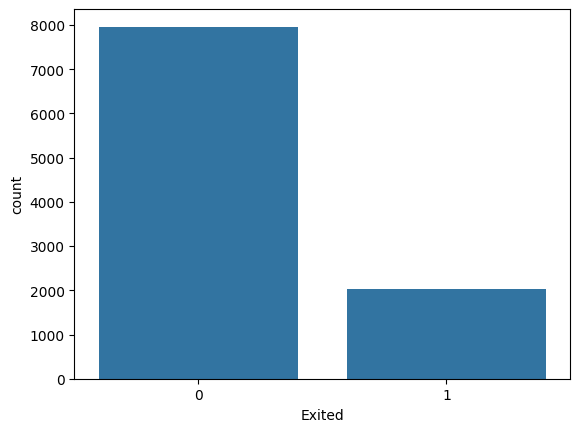

In [ ]:
sns.countplot(x='Exited',data=df)

<Axes: >

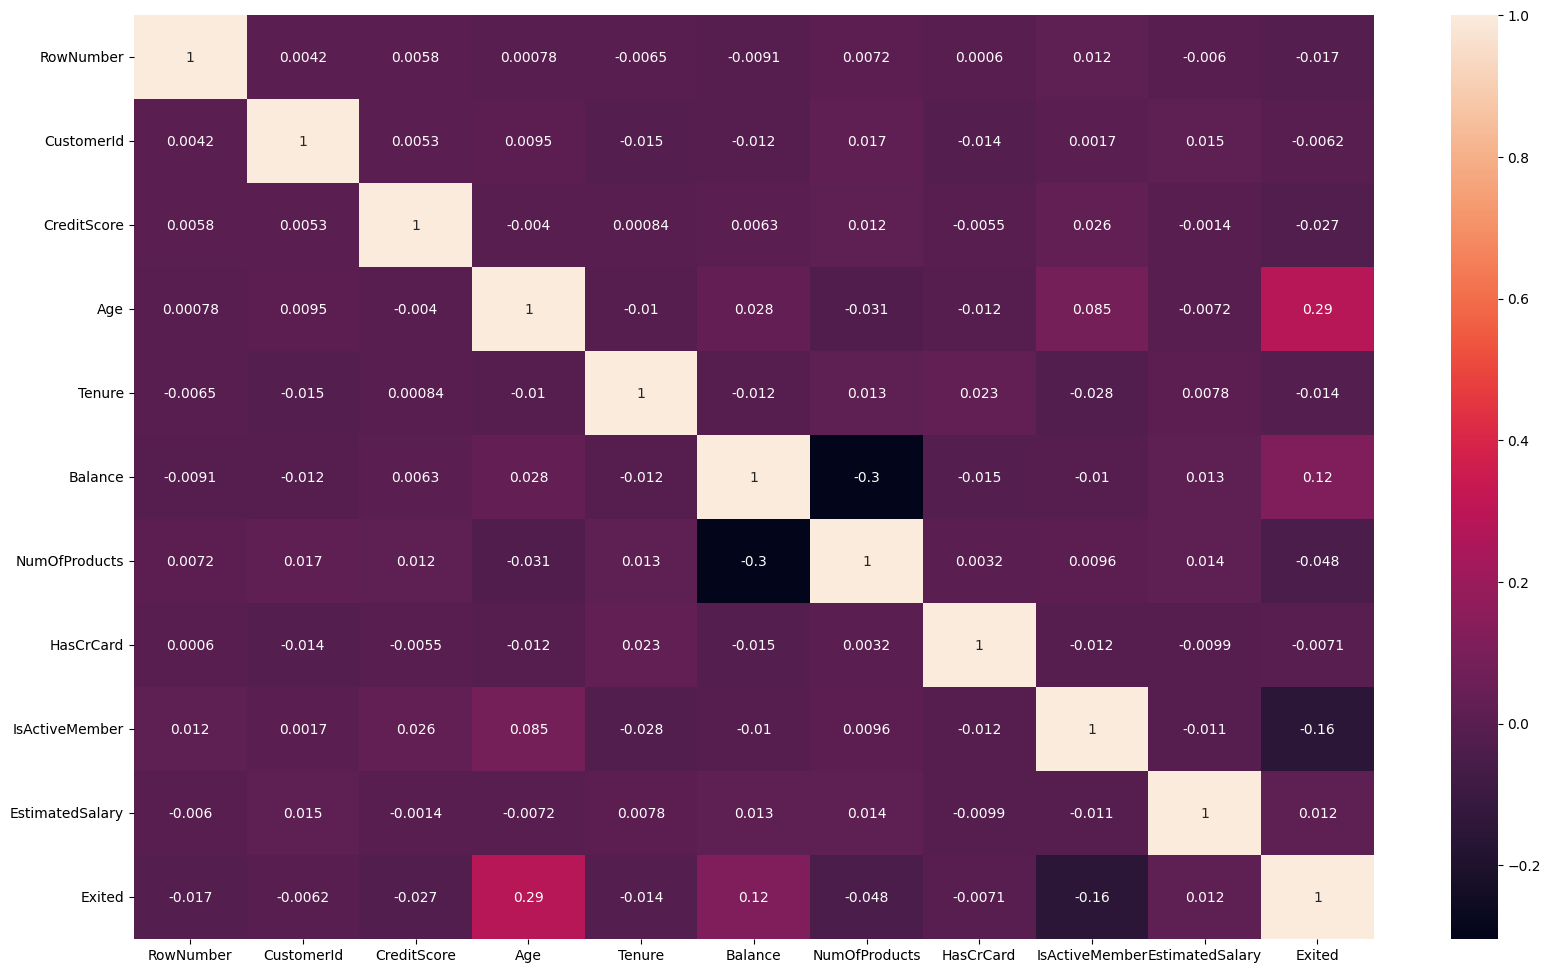

In [ ]:
plt.figure(figsize=(20,12))
sns.heatmap(df.select_dtypes(include='number').corr(),annot=True)


In [ ]:
from sklearn.preprocessing import StandardScaler ,LabelEncoder
for i in df.select_dtypes(include=['object']).columns:
    print(i)
    l=LabelEncoder()                                           # to convert categorial data to numerical data(labelEncoder())
    df[i]=l.fit_transform(df[i])



Surname
Geography
Gender


In [ ]:
x = df.drop(['Exited', 'RowNumber','Surname','CustomerId'], axis=1)

y = df['Exited']


In [ ]:
from sklearn.preprocessing import StandardScaler
s=StandardScaler()
x=s.fit_transform(x)

In [ ]:
from sklearn.model_selection import train_test_split

from imblearn.over_sampling import SMOTE #Synthetic minority over sampling

x_train, x_test, y_train, y_test = train_test_split(x,y, train_size=0.8, random_state=42)

smote = SMOTE()
x_train_res, y_train_res = smote.fit_resample(x_train, y_train)



In [ ]:
classifier = Sequential()

In [ ]:
# in this we are adding a input layer
classifier.add(Dense(units=10))
# dense represents the number of neurons created based in number of columns
# we are using activation relu so that the neuron is activated

In [ ]:
# In this we are adding the first hidden and second hidden layer and we can add how much ever layers
classifier.add(Dense(units=6,activation='relu')) # Here we are adding 6 neurons in first layer
classifier.add(Dense(units=10,activation='relu')) # Here we are adding 10 neurons in second layer

In [ ]:
# In this we are adding the output layer in this model
# In this sequential model it will understand of its own which is input,hidden and output layer as
# If it is a functional model we need to initialize each in next step for the model to understand input
classifier.add(Dense(units=1, activation='sigmoid'))
# Here we use sigmoid in the output activation

In [ ]:
classifier.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"])

In [ ]:
model_history= classifier.fit(x_train_res,y_train_res,validation_split=0.33,batch_size=100,epochs=100)

Epoch 1/100
86/86 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6285 - loss: 0.6471 - val_accuracy: 0.0846 - val_loss: 1.0499
Epoch 2/100
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7555 - loss: 0.5538 - val_accuracy: 0.1209 - val_loss: 1.1239
Epoch 3/100
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7609 - loss: 0.5198 - val_accuracy: 0.1850 - val_loss: 1.1407
Epoch 4/100
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7627 - loss: 0.5004 - val_accuracy: 0.2513 - val_loss: 1.1180
Epoch 5/100
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7719 - loss: 0.4872 - val_accuracy: 0.3204 - val_loss: 1.0776
Epoch 6/100
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7786 - loss: 0.4784 - val_accuracy: 0.3304 - val_loss: 1.1014
Epoch 7/100
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7837 - loss: 0.4727 - val_accuracy: 0.3671 - val_loss: 1.0597
Epoch 8/100
86/86 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7868 - loss: 0.4684 - val_accuracy: 0.3631 - v

In [ ]:
# predicting the test set results
y_pred = classifier.predict(x_test)
y_pred_thresholed = (y_pred>0.5).astype(int)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [ ]:
# making the confusion matrix
cm = confusion_matrix(y_test,y_pred_thresholed)
cm

array([[1501,  106],
       [ 180,  213]])

In [ ]:
# Evaluate model on training data
train_loss, train_accuracy = classifier.evaluate(x_train_res, y_train_res, verbose=0)

print(f"Training Loss: {train_loss:.4f}")
print(f"Training Accuracy: {train_accuracy:.4f}")

In [ ]:
from sklearn.metrics import accuracy_score
#calculate the accuracy score
accuracy_score(y_test,y_pred_thresholed)

0.857

In [ ]:
from sklearn.metrics import classification_report, roc_auc_score

print(classification_report(y_test, y_pred_thresholed))
print("ROC-AUC Score:", roc_auc_score(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.89      0.93      0.91      1607
           1       0.67      0.54      0.60       393

    accuracy                           0.86      2000
   macro avg       0.78      0.74      0.76      2000
weighted avg       0.85      0.86      0.85      2000

ROC-AUC Score: 0.8521560412381581


In [ ]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_split=5, random_state=42)
rf.fit(x_train_res, y_train_res)
y_pred1 = rf.predict(x_test)
train=rf.score(x_train_res,y_train_res)
print(train)
print("Accuracy:", accuracy_score(y_test, y_pred1))

0.9005663939584645
Accuracy: 0.8245


In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
gb = GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=4, random_state=42)
gb.fit(x_train_res, y_train_res)
y_pred2 = gb.predict(x_test)
train1=gb.score(x_train_res,y_train_res)
print(train1)
print("Accuracy:", accuracy_score(y_test, y_pred2))

0.8925424795468848
Accuracy: 0.85


In [ ]:
from xgboost import XGBClassifier
xg=XGBClassifier()
xg.fit(x_train_res, y_train_res)
y_pred3 = xg.predict(x_test)
train2=xg.score(x_train_res,y_train_res)
print(train2)
print("Accuracy:", accuracy_score(y_test, y_pred3))

0.9668030207677785
Accuracy: 0.853
